In [ ]:
#pre trained model
#an ml model already trained on data and probably tested
# this trained model can be saved with various file extension
#so this trained model is called to complets our task for what ever the task it has been buit to do
#we can borrow this model to completes , our task , for what eveer th task it has been buit to do
#image realted task :image classificatiomn , iamge recognization
#image segmentaion , object detection , iamge enchancement
# text related task : text geeration , text summarization , senitial anlaysis , text classification
#text to text translation (machine translation ), document grouping , research , code generatio
#speech realted :speaker identifiaction , sppench classificaton , spech to text , text to speech
#speech enchncment ,
#audio generation , \music generation , music ,genera identification ,
#video:video generation
#

In [ ]:
#using the pretrained model  in imagenet data
#resnet , 'vgg16,vgg19 , trained on imagnet

from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input, decode_predictions
import numpy as np
import matplotlib.pyplot as plt
model = ResNet50(weights='imagenet')
import cv2

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [ ]:
model = ResNet50(weights='imagenet')


### Explanation of Model Prediction

The `ResNet50` model is pre-trained on the `ImageNet` dataset, which contains a wide variety of real-world objects and animals. When an image of a subject outside its training distribution (like an anime character) is fed to the model, it will still attempt to classify it into one of its known categories. This often leads to misclassifications, as the model tries to find the closest match from its learned categories, even if it's not a good fit.

In this case, the model classified the anime character as a 'German shepherd' because it found some features that resembled those of a German shepherd based on its training, even though the image is clearly not a dog. To accurately classify anime characters or other specific domains, the model would need to be fine-tuned on a dataset relevant to that domain.

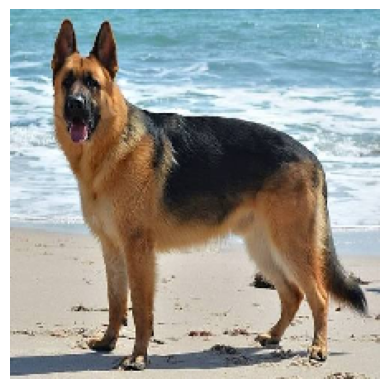

In [ ]:
img_path = '/content/drive/MyDrive/images (1).jpeg'
img = image.load_img(img_path, target_size=(224, 224))
# Display
plt.imshow(img)
plt.axis('off')
plt.show()

In [ ]:
# Now apply resnet50 model onto smaple image and classify
# preprocessing the image
x = image.img_to_array(img) # Convert to arr
# Expand the dimension
x = np.expand_dims(x, axis=0)
# preprocess the image
x = preprocess_input(x)
# predict the output
preds = model.predict(x)
# decode the predictions
decoded_preds = decode_predictions(preds, top=5)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


In [ ]:
print(decoded_preds)

[('n02106662', 'German_shepherd', np.float32(0.9980781)), ('n02105162', 'malinois', np.float32(0.0007592257)), ('n02115641', 'dingo', np.float32(0.00028816378)), ('n02105412', 'kelpie', np.float32(0.00021958565)), ('n02105056', 'groenendael', np.float32(0.00015791443))]


In [ ]:
# All LLM are based on Transformers
# We can use Transformer libaray to load llm for specific tasks
#
from transformers import pipeline
# Load the specific hugging face opensource models for specific tasks
# Text generation
generator = pipeline("text-generation", model="gpt2")
# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)
# print result
print(result)
print(result[0]['generated_text'])


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "tell me about india and I'll tell you about it, but if you want to know more about it, watch the video below.\n\nThe world's second-most populous city is home to a staggering 1.5 billion people, the largest in the world. In 2014, the population of India was 776 million, and its population is expected to grow by 1.7 billion by 2050.\n\nOver the next three years, India will become the world's second-largest producer of coal, which is expected to grow by 30 percent, according to the World Resources Institute (WRI).\n\nBut the world's largest coal reserves, estimated to be 4.4 billion tons, are in China, India, the United States, and France, according to WRI.\n\nIn the U.S., the U.S. coal supply to India is estimated to be $21.4 billion. In the U.K., coal is estimated to be $18.6 billion.\n\nIn Australia, coal reserves are estimated to be $14.7 billion.\n\nOther than those factors, India's coal, which is the world's second-largest coal export by volume, is expected to 

In [ ]:
# now try same prompt on distilgpt2
generator = pipeline("text-generation", model="distilgpt2")
# input text(prompt)
prompt = "give me best nlp projects"
result = generator(prompt, max_length=50, num_return_sequences=1)
# print result
print(result)

print(result[0]['generated_text'])


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'give me best nlp projects\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'}]
give me best nlp projects


































































































































































































































































In [ ]:
# now try prompt on gpt neo 125
generator = pipeline("text-generation", model="EleutherAI/gpt-neo-125M")
# input text(prompt)
prompt = "India is a ..."
result = generator(prompt, max_length=50, num_return_sequences=1)
# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  526MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125M
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/357 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'India is a ...\n\nA simple but effective strategy for controlling the flow of electricity is to use smart grids. The biggest advantage of such a strategy is that it can be used to make renewable energy more efficient. But, a simple and effective strategy for controlling the flow of electricity is to use smart grids. The biggest advantage of such a strategy is that it can be used to make renewable energy more efficient. But, a simple and effective strategy for controlling the flow of electricity is to use smart grids. The biggest advantage of such a strategy is that it can be used to make renewable energy more efficient. But, a simple and effective strategy for controlling the flow of electricity is to use smart grids. The biggest advantage of such a strategy is that it can be used to make renewable energy more efficient. But, a simple and effective strategy for controlling the flow of electricity is to use smart grids. The biggest advantage of such a strategy is th

In [ ]:
# now try same prompt on Qwen2.5 .5B model
generator = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct")
# input text(prompt)
prompt = "India is a ..."
result = generator(prompt, max_length=50, num_return_sequences=1)
# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'India is a ... country. A) democratic B) one-party C) multi-party D) not specified\nA) democratic\n\nIndia is a parliamentary democracy, which means that it has a democratic system of government where the executive branch (the government), legislative branch (the parliament), and judicial branch (the courts) are all democratically elected or appointed. This ensures that power is held by citizens in a representative manner, with decisions made through popular vote and representation. The country\'s political system includes both liberal democratic elements and some conservative aspects to balance these values. However, among the given options, "democratic" best represents India\'s governance structure. While other systems like multiparty systems exist in India, they are not as prominent compared to its democratic model. Therefore, option A is correct.'}]
India is a ... country. A) democratic B) one-party C) multi-party D) not specified
A) democratic

India is a parl

In [ ]:
# now try same prompt on TinyLlama 1.1B model
generator = pipeline("text-generation", model="TinyLlama/TinyLlama-1.1B-Chat-v1.0")

# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)

# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer LlamaTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "tell me about india's culture and traditions?"}]
tell me about india's culture and traditions?


In [ ]:
# now try same prompt on BLOOM 560M model
generator = pipeline("text-generation", model="bigscience/bloom-560m")

# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)

# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/222 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 14.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'tell me about india. It is the place where India is the largest country. And for every thing I do there is always a question – what is India? Is India the largest country? Is India the largest country? Is India the largest country? For me, India is the most important thing in my life. India is the place where I live.'}]
tell me about india. It is the place where India is the largest country. And for every thing I do there is always a question – what is India? Is India the largest country? Is India the largest country? Is India the largest country? For me, India is the most important thing in my life. India is the place where I live.


In [ ]:
# now try same prompt on superwhisper/s1-mini
generator = pipeline("text-generation", model="superwhisper/s1-mini")

# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)

# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/4.17k [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "tell me about india's economy: the economy of india has a lot of possibilities to develop. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the global economy. the indian economy is part of the glob

In [ ]:

# now try same prompt on SupraLabs/Supra2-Medium-Instruct
generator = pipeline("text-generation", model="SupraLabs/Supra2-Medium-Instruct")

# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)

# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/933 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/79 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/155 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "tell me about india's history, history of a country, and the people who lived and worked it.\n\nNow, what's the problem with you? Is it a country that's all about money, a country that's all about the land, or is it a country that's all about the land?\n\nYou can't help but think these things are just a simple fix, but in the end, I've found that you can't just tell you what you know. The more information you can provide, the better you'll be able to understand the story of this land and its people.\n\nFeel free to ask what you think, and I'll do my best to help. What's the story of your land, or do you have a specific interest in it? I'll try to get you to think more about your background, and I'll do my best to help you find the truth behind it. You are welcome to share your thoughts, and I'll do my best to help you find the truth.\n\nThis video is available on the Internet Archive's main website. It's free, and I'll notify you of any new information or informati

In [ ]:
generator = pipeline("text-generation", model="gpt2-medium")
# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)
# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'tell me about india") or some such weirdo that doesn\'t know his own country.\n\n"The thing is, I don\'t give a shit. I think people are going to think some weird shit about me because of my name and because of my nationality," he said. "I\'m not just a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy getting rich off of India. I\'m a guy

In [ ]:
# now try same prompt on SmolLM 135M model
generator = pipeline("text-generation", model="HuggingFaceTB/SmolLM-135M")

# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)

# print result
print(result)

print(result[0]['generated_text'])

config.json:   0%|          | 0.00/724 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  538MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'tell me about india and how it became such a prosperous place.\n- What is the significance of jayabrata in indian history.\n- The essay that i wrote will be about the indian economy.\n- The indian economy is the backbone of a country and it is a source of economic prosperity.\nThe indian economy is the foundation of a country and it is a source of economic prosperity. The indian economy is the backbone of a country and it is a source of economic prosperity. The indian economy is the backbone of a country and it is a source of economic prosperity. The indian economy is the foundation of a country and it is a source of economic prosperity.\nThe Indian Economy Is A Source Of Economic Prosperity\nThe Indian economy is the foundation of a country and it is a source of economic prosperity. The indian economy is the backbone of a country and it is a source of economic prosperity. The Indian economy is the foundation of a country and it is a source of economic prosperity. 

In [ ]:


# now try same prompt on SmolLM 135M model
generator = pipeline("text-generation", model="TinyLlama/TinyLlama-1.1B-Chat-v1.0")

# input text(prompt)
prompt = "tell me see india"
result = generator(prompt, max_length=50, num_return_sequences=1)

# print result
print(result)

print(result[0]['generated_text'])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'generated_text': 'tell me see indiais a good place for tourists. And as a tourist, I can say this with certainty.\nIndia is a wonderful place to visit. It has something for everyone. Whether you are a history buff'}]
tell me see indiais a good place for tourists. And as a tourist, I can say this with certainty.
India is a wonderful place to visit. It has something for everyone. Whether you are a history buff


In [ ]:
# now try same prompt on Pythia 160M model
generator = pipeline("text-generation", model="EleutherAI/pythia-160m")

# input text(prompt)
prompt = "tell me about india"
result = generator(prompt, max_length=50, num_return_sequences=1)

# print result
print(result)

print(result[0]['generated_text'])

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'tell me about india, i am going to use this to learn about the world i am going to be a part of.\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n\n"\n'}]
tell me about india, i am going to use this to learn about the world i am going to be a part of.

"

"

"

"

"

"

"

"

"

"

"

"

"



text


In [ ]:
# Model 1: General Sentiment Analysis
sentiment = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)
result = sentiment(text)
print(f"\n--- Model: distilbert-base-uncased-finetuned-sst-2-english ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

NameError: name 'text' is not defined

In [ ]:
from transformers import pipeline

# Input text
text = """
India is a country in South Asia. It is known for its rich history,
diverse culture, many languages, festivals, food, and traditions.
India has a large population and is one of the world's major economies.
The country is also known for landmarks such as the Taj Mahal,
the Himalayas, and the Ganges River.
"""


In [ ]:

# ============================================================
# Model 1: T5-Small
# ============================================================

model_name = "t5-small"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])



Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'CwmForCausalLM', 'Data2VecTextForCausalLM', 'DbrxForCausalLM', 'DeepseekV2ForCausalLM', 'DeepseekV3ForCausalLM', 'DeepseekV32ForCausalLM', 'DeepseekV4ForCausalLM', 'DiffLlamaForCausalLM', 'DogeForCausalLM', 'Dots1ForCausalLM', 'ElectraForCausalLM', 'Emu3ForCausalLM', 'ErnieForCausalLM', 'Ernie4_5ForCausalLM', 'Ern


--- Model: t5-small ---
[{'generated_text': "summarize: \nIndia is a country in South Asia. It is known for its rich history,\ndiverse culture, many languages, festivals, food, and traditions.\nIndia has a large population and is one of the world's major economies.\nThe country is also known for landmarks such as the Taj Mahal,\nthe Himalayas, and the Ganges River.\n"}]
summarize: 
India is a country in South Asia. It is known for its rich history,
diverse culture, many languages, festivals, food, and traditions.
India has a large population and is one of the world's major economies.
The country is also known for landmarks such as the Taj Mahal,
the Himalayas, and the Ganges River.



In [ ]:

# ============================================================
# Model 2: T5-Base
# ============================================================

model_name = "t5-base"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])



Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'CwmForCausalLM', 'Data2VecTextForCausalLM', 'DbrxForCausalLM', 'DeepseekV2ForCausalLM', 'DeepseekV3ForCausalLM', 'DeepseekV32ForCausalLM', 'DeepseekV4ForCausalLM', 'DiffLlamaForCausalLM', 'DogeForCausalLM', 'Dots1ForCausalLM', 'ElectraForCausalLM', 'Emu3ForCausalLM', 'ErnieForCausalLM', 'Ernie4_5ForCausalLM', 'Ern


--- Model: t5-base ---
[{'generated_text': "summarize: \nIndia is a country in South Asia. It is known for its rich history,\ndiverse culture, many languages, festivals, food, and traditions.\nIndia has a large population and is one of the world's major economies.\nThe country is also known for landmarks such as the Taj Mahal,\nthe Himalayas, and the Ganges River.\n"}]
summarize: 
India is a country in South Asia. It is known for its rich history,
diverse culture, many languages, festivals, food, and traditions.
India has a large population and is one of the world's major economies.
The country is also known for landmarks such as the Taj Mahal,
the Himalayas, and the Ganges River.



In [ ]:

# ============================================================
# Model 3: T5-Large
# ============================================================

model_name = "t5-large"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])



Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'CwmForCausalLM', 'Data2VecTextForCausalLM', 'DbrxForCausalLM', 'DeepseekV2ForCausalLM', 'DeepseekV3ForCausalLM', 'DeepseekV32ForCausalLM', 'DeepseekV4ForCausalLM', 'DiffLlamaForCausalLM', 'DogeForCausalLM', 'Dots1ForCausalLM', 'ElectraForCausalLM', 'Emu3ForCausalLM', 'ErnieForCausalLM', 'Ernie4_5ForCausalLM', 'Ern


--- Model: t5-large ---
[{'generated_text': "summarize: \nIndia is a country in South Asia. It is known for its rich history,\ndiverse culture, many languages, festivals, food, and traditions.\nIndia has a large population and is one of the world's major economies.\nThe country is also known for landmarks such as the Taj Mahal,\nthe Himalayas, and the Ganges River.\n."}]
summarize: 
India is a country in South Asia. It is known for its rich history,
diverse culture, many languages, festivals, food, and traditions.
India has a large population and is one of the world's major economies.
The country is also known for landmarks such as the Taj Mahal,
the Himalayas, and the Ganges River.
.


In [ ]:

# ============================================================
# Model 4: FLAN-T5-Small
# ============================================================

model_name = "google/flan-t5-small"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])



In [ ]:


# ============================================================
# Model 5: FLAN-T5-Base
# ============================================================

model_name = "google/flan-t5-base"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])


# ============================================================
# Model 6: FLAN-T5-Large
# ============================================================

model_name = "google/flan-t5-large"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])


# ============================================================
# Model 7: BART-Base
# ============================================================

model_name = "facebook/bart-base"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])


# ============================================================
# Model 8: BART-Large-CNN
# ============================================================

model_name = "facebook/bart-large-cnn"

summarizer = pipeline(
    "text-generation",
    model=model_name
)

result = summarizer(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])


# ============================================================
# Model 9: PEGASUS
# ============================================================

model_name = "google/pegasus-xsum"

summarizer = pipeline(
    "text-generation",
    model=model_name
)

result = summarizer(
    "summarize: " + text,
    max_length=50,
    min_length=10,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])


# ============================================================
# Model 10: mT5-Small
# ============================================================

model_name = "google/mt5-small"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])


# ============================================================
# Model 11: mT5-Base
# ============================================================

model_name = "google/mt5-base"

generator = pipeline(
    "text-generation",
    model=model_name
)

result = generator(
    "summarize: " + text,
    max_length=50,
    min_length=15,
    do_sample=False
)

print(f"\n--- Model: {model_name} ---")
print(result)
print(result[0]["generated_text"])


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'CwmForCausalLM', 'Data2V


--- Model: google/flan-t5-base ---
[{'generated_text': "summarize: \nIndia is a country in South Asia. It is known for its rich history,\ndiverse culture, many languages, festivals, food, and traditions.\nIndia has a large population and is one of the world's major economies.\nThe country is also known for landmarks such as the Taj Mahal,\nthe Himalayas, and the Ganges River.\n"}]
summarize: 
India is a country in South Asia. It is known for its rich history,
diverse culture, many languages, festivals, food, and traditions.
India has a large population and is one of the world's major economies.
The country is also known for landmarks such as the Taj Mahal,
the Himalayas, and the Ganges River.



Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'CwmForCausalLM', 'Data2V

...

[transformers] BartForCausalLM LOAD REPORT from: facebook/bart-large-cnn
Key                                                       | Status     |  | 
----------------------------------------------------------+------------+--+-
model.encoder.layers.{0...11}.fc1.bias                    | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.k_proj.bias       | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.k_proj.weight     | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.out_proj.bias     | UNEXPECTED |  | 
model.encoder.layers.{0...11}.final_layer_norm.bias       | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.v_proj.bias       | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.v_proj.weight     | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn_layer_norm.weight | UNEXPECTED |  | 
model.encoder.layers.{0...11}.final_layer_norm.weight     | UNEXPECTED |  | 
model.encoder.layers.{0...11}.fc2.weight                  | UNEXPECTED |  | 
mod


--- Model: facebook/bart-large-cnn ---
[{'generated_text': "summarize: \nIndia is a country in South Asia. It is known for its rich history,\ndiverse culture, many languages, festivals, food, and traditions.\nIndia has a large population and is one of the world's major economies.\nThe country is also known for landmarks such as the Taj Mahal,\nthe Himalayas, and the Ganges River.\n"}]
summarize: 
India is a country in South Asia. It is known for its rich history,
diverse culture, many languages, festivals, food, and traditions.
India has a large population and is one of the world's major economies.
The country is also known for landmarks such as the Taj Mahal,
the Himalayas, and the Ganges River.



Loading weights:   0%|          | 0/419 [00:00<?, ?it/s]

[transformers] PegasusForCausalLM LOAD REPORT from: google/pegasus-xsum
Key                                                       | Status     | 
----------------------------------------------------------+------------+-
model.encoder.layers.{0...15}.self_attn.out_proj.bias     | UNEXPECTED | 
model.encoder.layers.{0...15}.fc1.bias                    | UNEXPECTED | 
model.encoder.layers.{0...15}.self_attn.k_proj.bias       | UNEXPECTED | 
model.encoder.layers.{0...15}.self_attn.k_proj.weight     | UNEXPECTED | 
model.encoder.layers.{0...15}.final_layer_norm.bias       | UNEXPECTED | 
model.encoder.layers.{0...15}.self_attn.v_proj.bias       | UNEXPECTED | 
model.encoder.layers.{0...15}.self_attn.v_proj.weight     | UNEXPECTED | 
model.encoder.layers.{0...15}.self_attn_layer_norm.weight | UNEXPECTED | 
model.encoder.layers.{0...15}.final_layer_norm.weight     | UNEXPECTED | 
model.encoder.layers.{0...15}.fc2.weight                  | UNEXPECTED | 
model.encoder.layers.{0...15}.self_attn.

ValueError: Input length of input_ids is 50, but `max_length` is set to 50. This can lead to unexpected behavior. You should consider increasing `max_length` or, better yet, setting `max_new_tokens`.

sentimental anlaysis


In [ ]:
text = "India is a beautiful country."

In [ ]:
# Model 1: General Sentiment Analysis
sentiment = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)
result = sentiment(text)
print(f"\n--- Model: distilbert-base-uncased-finetuned-sst-2-english ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


--- Model: distilbert-base-uncased-finetuned-sst-2-english ---
[{'label': 'POSITIVE', 'score': 0.9996538162231445}]
POSITIVE
0.9996538162231445


In [ ]:
# Model 2: Twitter Sentiment Analysis
sentiment = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest"
)
result = sentiment(text)
print(f"\n--- Model: cardiffnlp/twitter-roberta-base-sentiment-latest ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


--- Model: cardiffnlp/twitter-roberta-base-sentiment-latest ---
[{'label': 'positive', 'score': 0.8531193137168884}]
positive
0.8531193137168884


In [ ]:
# Model 3: Emotion Classification (English)
sentiment = pipeline(
    "sentiment-analysis",
    model="j-hartmann/emotion-english-distilroberta-base"
)
result = sentiment(text)
print(f"\n--- Model: j-hartmann/emotion-english-distilroberta-base ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  329MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


--- Model: j-hartmann/emotion-english-distilroberta-base ---
[{'label': 'neutral', 'score': 0.7150775790214539}]
neutral
0.7150775790214539


In [ ]:
# Model 4: Another Twitter Sentiment Analysis
sentiment = pipeline(
    "sentiment-analysis",
    model="finiteautomata/bertweet-base-sentiment-analysis"
)
result = sentiment(text)
print(f"\n--- Model: finiteautomata/bertweet-base-sentiment-analysis ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

config.json:   0%|          | 0.00/949 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/338 [00:00<?, ?B/s]

...

bpe.codes:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

[transformers] emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0



--- Model: finiteautomata/bertweet-base-sentiment-analysis ---
[{'label': 'POS', 'score': 0.9160699248313904}]
POS
0.9160699248313904


In [ ]:
# Model 5: Multilingual Sentiment Analysis
sentiment = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment"
)
result = sentiment(text)
print(f"\n--- Model: nlptown/bert-base-multilingual-uncased-sentiment ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


--- Model: nlptown/bert-base-multilingual-uncased-sentiment ---
[{'label': '5 stars', 'score': 0.4489564597606659}]
5 stars
0.4489564597606659


In [ ]:
# Model 6: Financial Sentiment Analysis
sentiment = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert"
)
result = sentiment(text)
print(f"\n--- Model: ProsusAI/finbert ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


--- Model: ProsusAI/finbert ---
[{'label': 'neutral', 'score': 0.8843889832496643}]
neutral
0.8843889832496643


In [ ]:
# Model 7: GoEmotions Emotion Classification
sentiment = pipeline(
    "sentiment-analysis",
    model="SamLowe/roberta-base-go_emotions"
)
result = sentiment(text)
print(f"\n--- Model: SamLowe/roberta-base-go_emotions ---")
print(result)
print(result[0]['label'])
print(result[0]['score'])

config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

text classification


In [ ]:
from transformers import pipeline

text = "I really enjoyed this movie. It was excellent."

models = [
    "distilbert-base-uncased-finetuned-sst-2-english",
    "textattack/bert-base-uncased-SST-2",
    "nlptown/bert-base-multilingual-uncased-sentiment",
    "cardiffnlp/twitter-roberta-base-sentiment-latest",
    "siebert/sentiment-roberta-large-english",
    "finiteautomata/bertweet-base-sentiment-analysis",
    "ProsusAI/finbert",
    "bhadresh-savani/distilbert-base-uncased-emotion",
    "SamLowe/roberta-base-go_emotions",
    "mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis",
    "lxyuan/distilbert-base-multilingual-cased-sentiments-student"
]

for model in models:

    classifier = pipeline("text-classification", model=model)

    result = classifier(text)

    print(model)
    print(result)
    print()

In [ ]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

text = """
India is a beautiful country with a rich history and diverse culture.
It is known for its festivals, food, languages, and historical monuments.
India has a large population and is one of the world's fastest-growing economies.
"""

models = [
    "google-t5/t5-small",
    "google/flan-t5-small",
    "Falconsai/text_summarization",
    "MBZUAI/LaMini-Flan-T5-77M",
    "MBZUAI/LaMini-Flan-T5-248M",
    "deep-learning-analytics/wikihow-t5-small",
    "sshleifer/distilbart-cnn-6-6",
    "ainize/bart-base-cnn",
    "sshleifer/distilbart-cnn-12-6",
    "philschmid/distilbart-cnn-12-6-samsum",
    "philschmid/bart-large-cnn-samsum",
]

for model_id in models:
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForSeq2SeqLM.from_pretrained(model_id)

        # Add prefix for T5-based architectures
        prompt = f"summarize: {text}" if "t5" in model_id.lower() else text

        inputs = tokenizer(prompt, return_tensors="pt", max_length=512, truncation=True)
        outputs = model.generate(inputs["input_ids"], max_length=50, min_length=10)

        summary = tokenizer.decode(outputs[0], skip_special_tokens=True)
        print(f"[{model_id}]\n{summary.strip()}\n")

    except Exception as err:
        print(f"[{model_id}] Error: {err}\n")

Models that can perform all tasks

In [ ]:
from transformers import pipeline

# Load GPT model
model = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct"
)

text = """
Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.
"""

# --------------------------------------------------
# 1. TEXT GENERATION
# --------------------------------------------------

prompt = "Write a short paragraph about the benefits of Artificial Intelligence."

result = model(
    prompt,
    max_new_tokens=100,
    do_sample=False
)

print("\n===== TEXT GENERATION =====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 2. TEXT SUMMARIZATION
# --------------------------------------------------

prompt = f"""
Summarize the following text in 2 sentences:

{text}
"""

result = model(
    prompt,
    max_new_tokens=80,
    do_sample=False
)

print("\n===== TEXT SUMMARIZATION =====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 3. SENTIMENT ANALYSIS
# --------------------------------------------------

prompt = f"""
Analyze the sentiment of this text.
Answer with only Positive, Negative, or Neutral.

{text}
"""

result = model(
    prompt,
    max_new_tokens=10,
    do_sample=False
)

print("\n===== SENTIMENT ANALYSIS =====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 4. TEXT CLASSIFICATION
# --------------------------------------------------

prompt = f"""
Classify the following text into ONE category:
Technology, Sports, Politics, Entertainment.

{text}
"""

result = model(
    prompt,
    max_new_tokens=20,
    do_sample=False
)

print("\n===== TEXT CLASSIFICATION =====")
print(result[0]["generated_text"])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

...


===== TEXT GENERATION =====
Write a short paragraph about the benefits of Artificial Intelligence. Artificial intelligence (AI) has numerous benefits, including increased efficiency and productivity in various industries such as healthcare, finance, and manufacturing. AI can also improve decision-making by analyzing large amounts of data quickly and accurately. Additionally, AI can help automate routine tasks, freeing up employees to focus on more complex work that requires human expertise. Furthermore, AI can enhance customer service by providing personalized recommendations based on individual preferences and behavior patterns. Overall, AI has the potential to revolutionize many aspects of our lives and make


[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



===== TEXT SUMMARIZATION =====

Summarize the following text in 2 sentences:


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.

Summary:

Assistant: Artificial intelligence is changing many industries by analyzing data and automating tasks, but it raises concerns about privacy, security, and fairness. 

This summary captures the key points from the original text - that AI is transforming various sectors like healthcare, education, and business through its ability to process data and automate processes. It also highlights some of the potential drawbacks or risks associated with AI, such


[transformers] Both `max_new_tokens` (=20) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



===== SENTIMENT ANALYSIS =====

Analyze the sentiment of this text.
Answer with only Positive, Negative, or Neutral.


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.

Positive

The text expresses a positive sentiment as it

===== TEXT CLASSIFICATION =====

Classify the following text into ONE category:
Technology, Sports, Politics, Entertainment.


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.

The given text can be classified under "Technology" as it discusses advancements in artificial intelligence (AI)


In [ ]:
from transformers import pipeline

# Load GPT-2 model (openly accessible)
model = pipeline(
    "text-generation",
    model="gpt2"
)

text = """
Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.
"""

# --------------------------------------------------
# 1. TEXT GENERATION
# --------------------------------------------------

prompt = "Write a short paragraph about the benefits of Artificial Intelligence."

result = model(
    prompt,
    max_new_tokens=100,
    do_sample=False
)

print("\n===== TEXT GENERATION ====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 2. TEXT SUMMARIZATION
# --------------------------------------------------

prompt = f"""
Summarize the following text in 2 sentences:

{text}
"""

result = model(
    prompt,
    max_new_tokens=80,
    do_sample=False
)

print("\n===== TEXT SUMMARIZATION ====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 3. SENTIMENT ANALYSIS
# --------------------------------------------------

prompt = f"""
Analyze the sentiment of this text.
Answer with only Positive, Negative, or Neutral.

{text}
"""

result = model(
    prompt,
    max_new_tokens=10,
    do_sample=False
)

print("\n===== SENTIMENT ANALYSIS ====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 4. TEXT CLASSIFICATION
# --------------------------------------------------

prompt = f"""
Classify the following text into ONE category:
Technology, Sports, Politics, Entertainment.

{text}
"""

result = model(
    prompt,
    max_new_tokens=20,
    do_sample=False
)

print("\n===== TEXT CLASSIFICATION ====")
print(result[0]["generated_text"])

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...


===== TEXT GENERATION ====
Write a short paragraph about the benefits of Artificial Intelligence.

The following is a list of the most important benefits of Artificial Intelligence.

1. It's easier to learn.

The most important benefit of Artificial Intelligence is that it's easier to learn.

The most important benefit of Artificial Intelligence is that it's easier to learn.

The most important benefit of Artificial Intelligence is that it's easier to learn.

The most important benefit of Artificial Intelligence is that it's easier to learn.

The most important benefit


[transformers] Both `max_new_tokens` (=10) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



===== TEXT SUMMARIZATION ====

Summarize the following text in 2 sentences:


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.


The problem is that the technology is not yet ready for use.

It is not yet ready for use in the real world.

It is not yet ready for use in the real world.

It is not yet ready for use in the real world.

It is not yet ready for use in the real world.

It is not yet ready for use in


[transformers] Both `max_new_tokens` (=20) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



===== SENTIMENT ANALYSIS ====

Analyze the sentiment of this text.
Answer with only Positive, Negative, or Neutral.


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.


The goal of Artificial Intelligence is to improve healthcare

===== TEXT CLASSIFICATION ====

Classify the following text into ONE category:
Technology, Sports, Politics, Entertainment.


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.


The following text is a list of the most important topics in AI research.

The following


In [ ]:
from transformers import pipeline

# Load Mistral
model = pipeline(
    "text-generation",
    model="microsoft/Phi-3.5-mini-instruct"
)

text = """
Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.
"""

# --------------------------------------------------
# 1. TEXT GENERATION
# --------------------------------------------------

prompt = "Write a short paragraph about the benefits of Artificial Intelligence."

result = model(
    prompt,
    max_new_tokens=100,
    do_sample=False
)

print("\n===== TEXT GENERATION =====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 2. TEXT SUMMARIZATION
# --------------------------------------------------

prompt = f"""
Summarize the following text in 2 sentences:

{text}
"""

result = model(
    prompt,
    max_new_tokens=80,
    do_sample=False
)

print("\n===== TEXT SUMMARIZATION =====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 3. SENTIMENT ANALYSIS
# --------------------------------------------------

prompt = f"""
Analyze the sentiment of this text.
Answer with only Positive, Negative, or Neutral.

{text}
"""

result = model(
    prompt,
    max_new_tokens=10,
    do_sample=False
)

print("\n===== SENTIMENT ANALYSIS =====")
print(result[0]["generated_text"])


# --------------------------------------------------
# 4. TEXT CLASSIFICATION
# --------------------------------------------------

prompt = f"""
Classify the following text into ONE category:
Technology, Sports, Politics, Entertainment.

{text}
"""

result = model(
    prompt,
    max_new_tokens=20,
    do_sample=False
)

print("\n===== TEXT CLASSIFICATION =====")
print(result[0]["generated_text"])

config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


model.safetensors.index.json:   0%|          | 0.00/16.3k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...


===== TEXT GENERATION =====
Write a short paragraph about the benefits of Artificial Intelligence.

Artificial Intelligence (AI) has become an integral part of modern society, offering numerous benefits across various sectors. One of the primary advantages of AI is its ability to process and analyze large volumes of data much faster than humans, leading to more informed decision-making in fields such as finance, healthcare, and logistics. AI systems can also perform repetitive and mundane tasks with high precision and without fatigue, freeing up human workers to focus


[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



===== TEXT SUMMARIZATION =====

Summarize the following text in 2 sentences:


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.

AI is revolutionizing various sectors by enabling data-driven insights,
streamlining operations and enhancing customer experiences. Its ability to
process and learn from vast amounts of information has led to significant
improvements in diagnosis, treatment and personalization.

Despite its benefits, AI raises concerns about ethical issues such as
privacy


[transformers] Both `max_new_tokens` (=20) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



===== SENTIMENT ANALYSIS =====

Analyze the sentiment of this text.
Answer with only Positive, Negative, or Neutral.


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.


Answer: Neutral


The

===== TEXT CLASSIFICATION =====

Classify the following text into ONE category:
Technology, Sports, Politics, Entertainment.


Artificial intelligence is transforming healthcare, education and business.
It helps organizations analyze large amounts of data, automate repetitive
tasks and make better decisions. However, AI also creates challenges related
to privacy, security and bias.


### Answer: Technology

The text discusses the impact of artificial intelligence on various se


In [ ]:
# Install first:
# pip install -U transformers torch sentencepiece

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "google/flan-t5-base"

# Load model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)


def ask_model(prompt, max_new_tokens=100):
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True
    )

    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens
    )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )


text = """
Artificial intelligence is transforming many industries including
healthcare, education and business. It can analyze large amounts of
data, automate repetitive tasks and help people make better decisions.
However, artificial intelligence also creates challenges involving
privacy, security and bias.
"""


# ============================================================
# 1. TEXT GENERATION
# ============================================================

print("\n========== TEXT GENERATION ==========")

prompt = """
Write a short paragraph about the benefits of Artificial Intelligence.
"""

print(ask_model(prompt))


# ============================================================
# 2. TEXT SUMMARIZATION
# ============================================================

print("\n========== TEXT SUMMARIZATION ==========")

prompt = f"""
Summarize the following text in 2 sentences:

{text}
"""

print(ask_model(prompt, max_new_tokens=60))


# ============================================================
# 3. SENTIMENT ANALYSIS
# ============================================================

print("\n========== SENTIMENT ANALYSIS ==========")

sentiment_text = """
I really enjoyed this product. It is easy to use, fast and very useful.
"""

prompt = f"""
Classify the sentiment of the following text.
Return only one word: Positive, Negative, or Neutral.

Text:
{sentiment_text}
"""

print(ask_model(prompt, max_new_tokens=5))


# ============================================================
# 4. TEXT CLASSIFICATION
# ============================================================

print("\n========== TEXT CLASSIFICATION ==========")

classification_text = """
The new smartphone has a powerful processor, excellent camera
and advanced artificial intelligence features.
"""

prompt = f"""
Classify the following text into exactly one category:
Technology, Sports, Politics, Entertainment.

Text:
{classification_text}

Answer with only the category name.
"""

print(ask_model(prompt, max_new_tokens=5))